# Lab Exercise 6: Furrier Fourier Transforms

## Fourier Transforms Example: Light Switch

Suppose we turn a light switch at $t=t_0-\tau/2$, and turn it off at $t=t_0+\tau/2$. We treat $\tau$ and $t_0$ as constant parameters. The light emitted during this interval has average frequency $\nu_0$, also a constant parameter.

The electric field (complex number!) emitted is:
$$E = E_0\text e^{-2 i\pi \nu_0 t}\quad \text{if}\quad t_0 - \frac\tau2\leq t\leq t_0 + \frac\tau2,\qquad E = 0\quad\text{otherwise}.$$

Apply the Fourier Transform formula to get the field in "frequency space", i.e. as a function of frequency $\nu$ rather than time $t$.
$$\hat E = \int_{t_0-\tau/2}^{t_0+\tau/2} E(t)\text e^{2\pi i (\nu-\nu_0) t} \text d \nu = E_0\tau \text e^{2\pi i (\nu-\nu_0) t_0}\underbrace{\frac{\sin\left[\pi(\nu-\nu_0)\tau\right]}{\pi(\nu-\nu_0)\tau}}_{=\text{sinc}\left[(\nu-\nu_0)\tau\right]},$$
where $\text{sinc}$ is called the Cardinal sine function.

Let's use parameters: $\tau = 1s,~t_0 = 10s,~\nu_0=5$ Hz

### Exercise 1

Calculate and plot the normalized real part of the field, $Re(E) / E_0$, from $t_0 - \frac\tau2\leq t\leq t_0 + \frac\tau2$. Hint: when discretizing time, try using 4096 values.

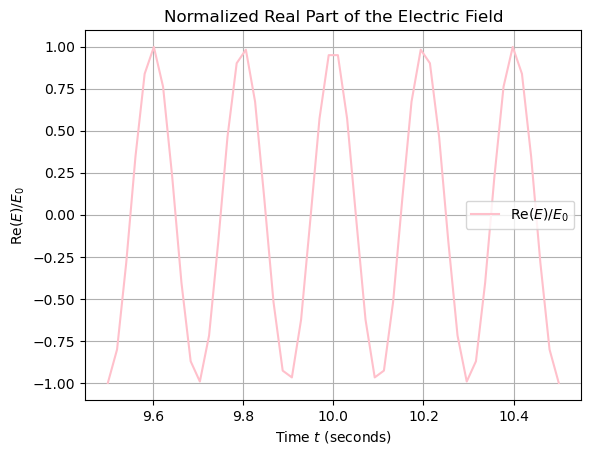

In [40]:
import numpy as np 
import matplotlib.pyplot as plt

tau = 1.0 #s
t0= 10 #s
v0 = 5 # Hz 
N = 4096

t = np.linspace (t0 - tau/2, t0 + tau/2)
normalized_real = np.cos(2 * np.pi * v0 * t)
plt.figure()
plt.plot(t, normalized_real, color='pink', label=r'$\text{Re}(E)/E_0$')
plt.title('Normalized Real Part of the Electric Field')
plt.xlabel('Time $t$ (seconds)')
plt.ylabel(r'$\text{Re}(E)/E_0$')
plt.grid(True)
plt.legend()
plt.show()

### Exercise 2

Now calculate, using the formula given (not using a packaged routine), the Fourier transform of the signal, i.e. $\hat{E}(\nu)$, for $0 \leq \nu \leq \nu_0$. Make two plots: $Re(\hat{E}) / (E_0 \tau)$ as a function of $\nu$, and $|\hat{E}| / (E_0 \tau) $ as a function of $\nu$. The second plot, which shows normalized amplitudes, is called the spectrum of the signal.

Note:
* Spectrum is centred around $\nu=\nu_0$, but non-negligible width (i.e. not all the light has frequency exactly $\nu_0$.) So the plane wave approximation doesn't exactly hold.
* If you increase duration or increase frequency: spectrum is narrower around $\nu=\nu_0$, and you have a better plane wave approximation.
* If you shorten duration or decrease frequency (e.g. pulsed laser): the frequency spreads out. (See https://www.nobelprize.org/prizes/physics/2023/press-release/ , Nobel Prize for attosecond lasers)
* Bandwidth theorem:
    $$\tau\Delta\nu \approx 1$$
    *You may recognize something like Heisenberg's uncertainty principle!*

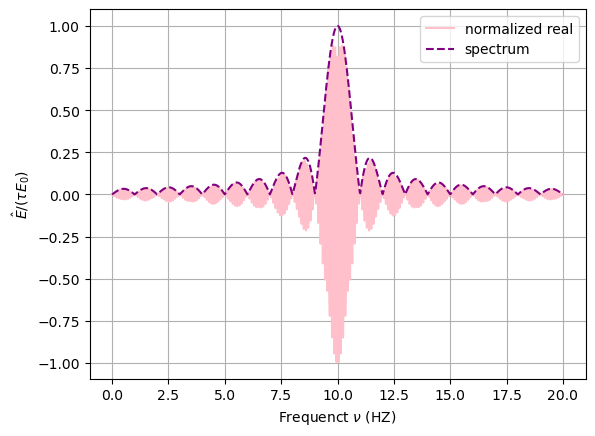

In [39]:
import numpy as np
import matplotlib.pyplot as plt

nuArray= np.linspace(0, 2*v0, N)
EhatArray = np.exp(2j*np.pi*(nuArray-v0)*t0)*np.sinc((nuArray-v0)*tau)
plt.plot(nuArray, np.real(EhatArray), label= 'normalized real', color = 'pink')
plt.plot(nuArray, np.abs(EhatArray), '--', label ='spectrum', color = 'purple')
plt.grid()
plt.xlabel(r'Frequenct $\nu$ (HZ)')
plt.ylabel(r'$\hat E / ( \tau E_0)$')
plt.legend()

## DFT Example: Pitch (Sound) Timeseries

Adapted from textbook's online material.

### Exercise 3

Using numpy.loadtxt, read in the text file "pitch.txt" provided. The values are floats. 

The file represents a "time series" of samples of the pitch of a sound wave, i.e. the next value in the series represents the pitch at the next sample. The samples are taken at a frequency of 44100 Hz.

Make a plot of pitch (arbitrary units) vs time.

Text(0.5, 1.0, 'pitch timeseries')

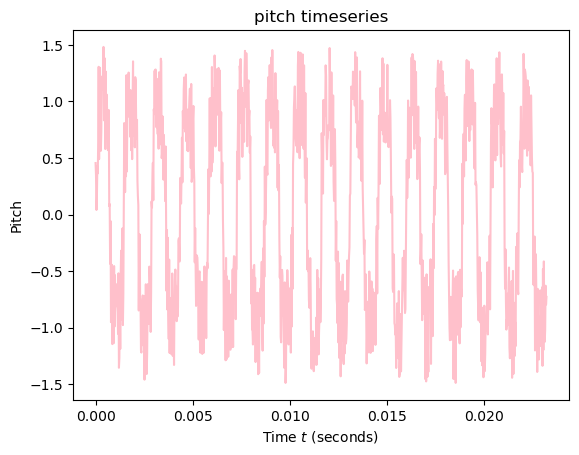

In [9]:
yArray= np.loadtxt("pitch.txt", float)
f = 44100.0 
dt = 1/f 
N = len(yArray)
tArray = np.arange(N)*dt
plt.plot(tArray, yArray, color = 'pink', label = 'pitch vs time')
plt.title('Pitch vs. Time graph')
plt.xlabel('Time $t$ (seconds)')
plt.ylabel(r'Pitch')
plt.title('pitch timeseries')

### Exercise 4

Perform a Discrete Fourier Transform on the time series "manually", using the following code snippet from the textbook. Time how long the transform takes. 

Plot the amplitudes (i.e. magnitudes) of the Fourier coefficients.

In [36]:
import numpy as np
def dft(y):
    N = len(y)
    c = np.zeros(N//2+1, complex)
    for k in range(N//2+1):
        for n in range(N):
            c[k] += y[n]*np.exp(-2j*np.pi*k*n/N)
    return c

In [14]:
from time import time 
dft_time = time()
yArray= np.loadtxt("pitch.txt", float)
cArray = dft(yArray)
dft_time = time() - dft_time
print (dft_time)

0.42963504791259766


(0.0, 500.0)

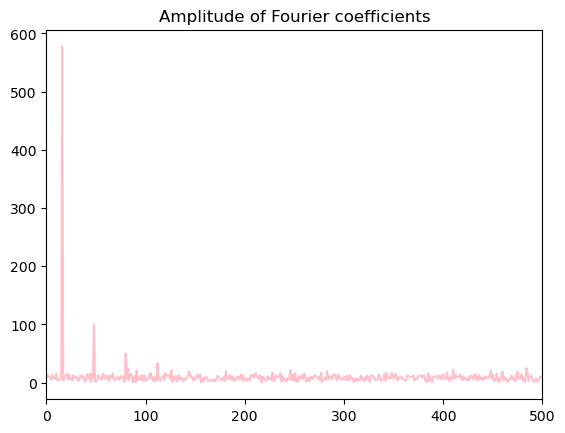

In [37]:
plt.plot(abs(cArray), color = 'pink')
plt.title('Amplitude of Fourier coefficients')
plt.xlim(0, 500)


### Exercise 5

Repeat Exercise 4, but using numpy.fft.rfft instead of the dft code snippet from the textbook. Which algorithm is faster, and by how much? How close are the transform results?

In [18]:
fft_time = time()
c2array = np.fft.rfft(yArray)
fft_time = time() - fft_time
print(fft_time)
print('homemade dft time - numpy fft time dft_time: ', dft_time - fft_time)
print('maximum |c2 - c|: ', max(abs(c2array-cArray)))

0.0005459785461425781
homemade dft time - numpy fft time dft_time:  0.4290890693664551
maximum |c2 - c|:  1.2336902285645956e-11


### Exercise 6

We now seek to "de-noise" the signal. We will treat the three highest-amplitude frequencies as our "signal" which we want to isolate, and everything else as the "noise" which we want to eliminate. 

Convert the Fourier coefficients to frequencies by dividing them by $T$ (the total length of the time interval covered by the time series.) Now you should have an array of frequencies and an array of corresponding amplitudes.

Sort the frequencies by amplitude (you can use numpy.argsort if you like). Print the three "signal" frequencies, and their corresponding amplitudes.

In [29]:
T = N*dt 
freqArray = np.arange(N//2+1)/T
MaxFreqs = np.argsort(abs(c2array)**2)
MaxDreqs = MaxFreqs [-1:-4:-1]
print('tope three frequencies and associated amplitudes: ')
print('{0:10.2f}. {1:10.2f}. {2:10.2f} Hz'.format(
    freqArray[MaxDreqs[0]],
    freqArray[MaxDreqs[1]],
    freqArray[MaxDreqs[2]]))
print('{0:10.2f}. {1:10.2f}. {2:10.2f}'.format(
    abs(c2array[MaxDreqs[0]]),
    abs(c2array[MaxDreqs[1]]),
    abs(c2array[MaxDreqs[2]])))


tope three frequencies and associated amplitudes: 
    689.06.    2067.19.    3445.31 Hz
    577.64.     100.46.      50.24


### Exercise 7

Now we will isolate the "noise".

Create a copy of the array of amplitudes (use numpy.copy). In the copy, zero out the largest three amplitudes (which you identified in the previous exercise). Inverse-transform the result, using np.fft.irfft, to get an array of pitch values. Plot it vs time.

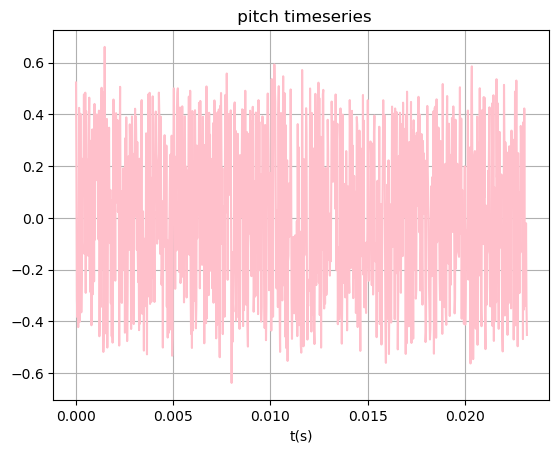

In [35]:
c2_filtarray = np.copy(c2array[:])
c2_filtarray[MaxDreqs] = 0.0
y_filtarray = np.fft.irfft(c2_filtarray)

plt.plot(tArray, y_filtarray, label = 'noise only', color= 'pink')
plt.xlabel('t(s)')
plt.title(' pitch timeseries')
plt.grid()

### Exercise 8

Finally, let's plot the signal, i.e. the data with the noise subtracted out. Subtract your Exercise 7 array of pitch values from your original (Exercise 3) array of pitch values. Plot the result vs time.

Does the plot look a lot different from the results of Exercise 3?

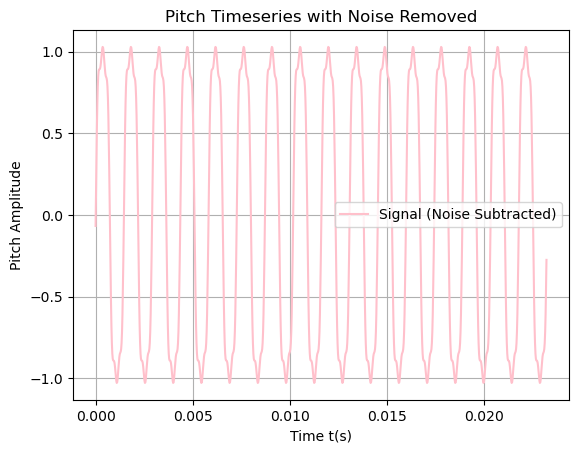

In [34]:
clean_signal = yArray - y_filtarray

plt.figure()
plt.plot(tArray, clean_signal, label='Signal (Noise Subtracted)', color='pink')
plt.title('Pitch Timeseries with Noise Removed')
plt.xlabel('Time t(s)')
plt.ylabel('Pitch Amplitude')
plt.grid(True)
plt.legend()
plt.show()

plot looks very different from exercise 3, while it has the same overall shape it no longer has additional dips and spikes everywhere due to the noise that hadn't been removed. 